# Heart Disease Prediction

Predicting heart disease from clinical data using Logistic Regression, Decision Tree and K Nearest Neighbours, with a focus on models that are accurate and easy to explain.

Dataset: UCI Heart Disease (Cleveland), 303 records and 14 features.

<a href="https://colab.research.google.com/github/sriram2708/heart-disease-prediction/blob/main/heart_disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [139]:
import pandas as pd

In [140]:
df = pd.read_csv('heart-disease.csv')

In [141]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Dataset Features

1. age = age in years

2. sex = sex (1 = male; 0 = female)

3. cp = chest pain type
  *   Value 1: typical angina
  *   Value 2: atypical angina
  *   Value 3: non-anginal pain
  *   Value 4: asymptomatic

4. trestbps = resting blood pressure (in mm Hg on admission to the hospital)

5. chol = serum cholestoral in mg/dl

6. fbs = (fasting blood sugar > 120 mg/dl) (1 = true; 0 = false)

7. restecg = resting electrocardiographic results
  *   Value 0: normal 
  *   Value 1: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV)
  *  Value 2: showing probable or definite left ventricular hypertrophy by Estes' criteria 

8. thalach = maximum heart rate achieved

9. exang: exercise induced angina (1 = yes; 0 = no)

10. oldpeak = ST depression induced by exercise relative to rest

11. slope = the slope of the peak exercise ST segment 
  *   Value 1: upsloping 
  *   Value 2: flat 
  *   Value 3: downsloping


12. ca = number of major vessels (0-3) colored by flourosopy

13. thal: 3 = normal; 6 = fixed defect; 7 = reversable defect

14. the predicted attribute

In [142]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [143]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        303 non-null    float64
 12  thal      303 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [144]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

## Checking for Missing Values

## Data Types


1.   Continuous data

  Continuous data is a type of numerical data that refers to the unspecified number of possible measurements between two realistic points. These numbers are not always clean and tidy like those in discrete data, as they're usually collected from precise measurements. Over time, measuring a particular subject allows us to create a defined range, where we can reasonably expect to collect more data. Continuous data is all about accuracy. Variables in these data sets often carry decimal points, with the number to the right stretched out as far as possible. This level of detail is paramount for scientists, doctors, and manufacturers, to name a few.
2.   Categorical data

  Categorical data is the statistical data comprising categorical variables of data that are converted into categories. One of the examples is a grouped data. More precisely, categorical data could be derived from qualitative data analysis that are countable, or from quantitative data analysis grouped within given intervals. These data are summarised in the form of a probability table. However, when we consider data analysis, it is referred to use the term “categorical data”, which is applied to data sets. Also, it is to be noted that, while containing some categorical variables, the data set may also contain non-categorical variables.


## Correlation: Heatmap, Pair Plot and Cluster Map

1.   Heatmap

  Heatmap, pair plot, and cluster map are all data visualization techniques that are commonly used in data analysis and machine learning tasks. They provide a visual representation of the relationships between variables in a dataset and can help to identify patterns, correlations, and clusters. A heatmap is a graphical representation of a matrix, where the values are represented by colors. In the context of data analysis, a heatmap is typically used to show the correlation between pairs of variables in a dataset. A heatmap can help to identify which variables are strongly correlated with each other, and which ones are not. Heatmaps are commonly used in exploratory data analysis (EDA) and can provide valuable insights into the structure of a dataset.

2.  Pair plot

  A pair plot is a matrix of scatter plots, where each variable is plotted against every other variable in the dataset. Pair plots can help to visualize the relationships between pairs of variables, and can also reveal any patterns or trends in the data. Pair plots are useful for EDA and can provide insights into the structure and distribution of the data.

3. Cluster map

  A cluster map is a heatmap with hierarchical clustering applied to both rows and columns. In a cluster map, the rows and columns are clustered based on their similarity, and the resulting clusters are displayed as dendrograms on the sides of the heatmap. Cluster maps can help to identify patterns and clusters in the data, and can also reveal any relationships between variables that may not be apparent from a simple heatmap. Cluster maps are commonly used in machine learning tasks, such as clustering and classification, and can help to guide the selection of features and models.

Overall, heatmap, pair plot, and cluster map are all useful data visualization techniques that can provide valuable insights into the relationships between variables in a dataset. They are commonly used in data analysis and machine learning tasks, and can help to guide the selection of features and models, as well as provide insights into the structure and distribution of the data

In [145]:
df['sex'].unique()

array([1., 0.])

In [146]:
from sklearn.preprocessing import LabelEncoder
sex_enc=LabelEncoder()

In [147]:
df['sex'] = sex_enc.fit_transform(df['sex'])

In [148]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [149]:
data=pd.get_dummies(df , columns =['sex'])

In [150]:
data.head()

,age,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,sex_0,sex_1
0,63.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,False,True
1,67.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1,False,True
2,67.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,False,True
3,37.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,False,True
4,41.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,True,False


In [151]:
data.corr()

,age,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,sex_0,sex_1
age,1.000000,0.104139,0.284946,0.208950,0.118530,0.148868,-0.393806,0.091661,0.203805,0.161770,0.365323,0.128303,0.223120,0.097542,-0.097542
cp,0.104139,1.000000,-0.036077,0.072319,-0.039975,0.067505,-0.334422,0.384060,0.202277,0.152050,0.233117,0.262089,0.414446,-0.010084,0.010084
trestbps,0.284946,-0.036077,1.000000,0.130120,0.175340,0.146560,-0.045351,0.064762,0.189171,0.117382,0.097528,0.134424,0.150825,0.064456,-0.064456
chol,0.208950,0.072319,0.130120,1.000000,0.009841,0.171043,-0.003432,0.061310,0.046564,-0.004062,0.123726,0.018351,0.085164,0.199915,-0.199915
fbs,0.118530,-0.039975,0.175340,0.009841,1.000000,0.069564,-0.007854,0.025665,0.005747,0.059894,0.140764,0.064625,0.025264,-0.047862,0.047862
restecg,0.148868,0.067505,0.146560,0.171043,0.069564,1.000000,-0.083389,0.084867,0.114133,0.133946,0.131749,0.024325,0.169202,-0.021647,0.021647
thalach,-0.393806,-0.334422,-0.045351,-0.003432,-0.007854,-0.083389,1.000000,-0.378103,-0.343085,-0.385601,-0.265699,-0.274142,-0.417167,0.048663,-0.048663
exang,0.091661,0.384060,0.064762,0.061310,0.025665,0.084867,-0.378103,1.000000,0.288223,0.257748,0.145788,0.325240,0.431894,-0.146201,0.146201
oldpeak,0.203805,0.202277,0.189171,0.046564,0.005747,0.114133,-0.343085,0.288223,1.000000,0.577537,0.301067,0.342405,0.424510,-0.102173,0.102173
slope,0.161770,0.152050,0.117382,-0.004062,0.059894,0.133946,-0.385601,0.257748,0.577537,1.000000,0.110803,0.286792,0.339213,-0.037533,0.037533


<Axes: >

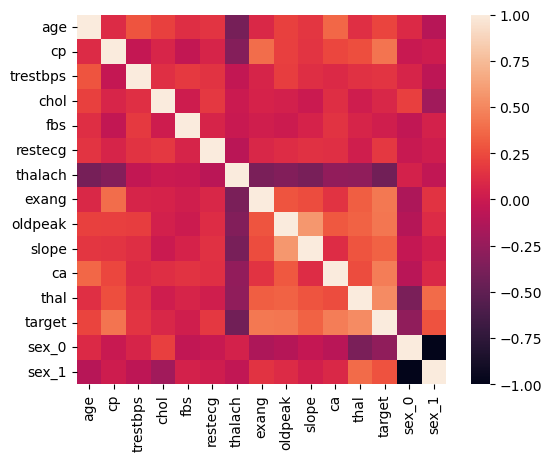

In [152]:
sns.heatmap(data.corr() , square = True)

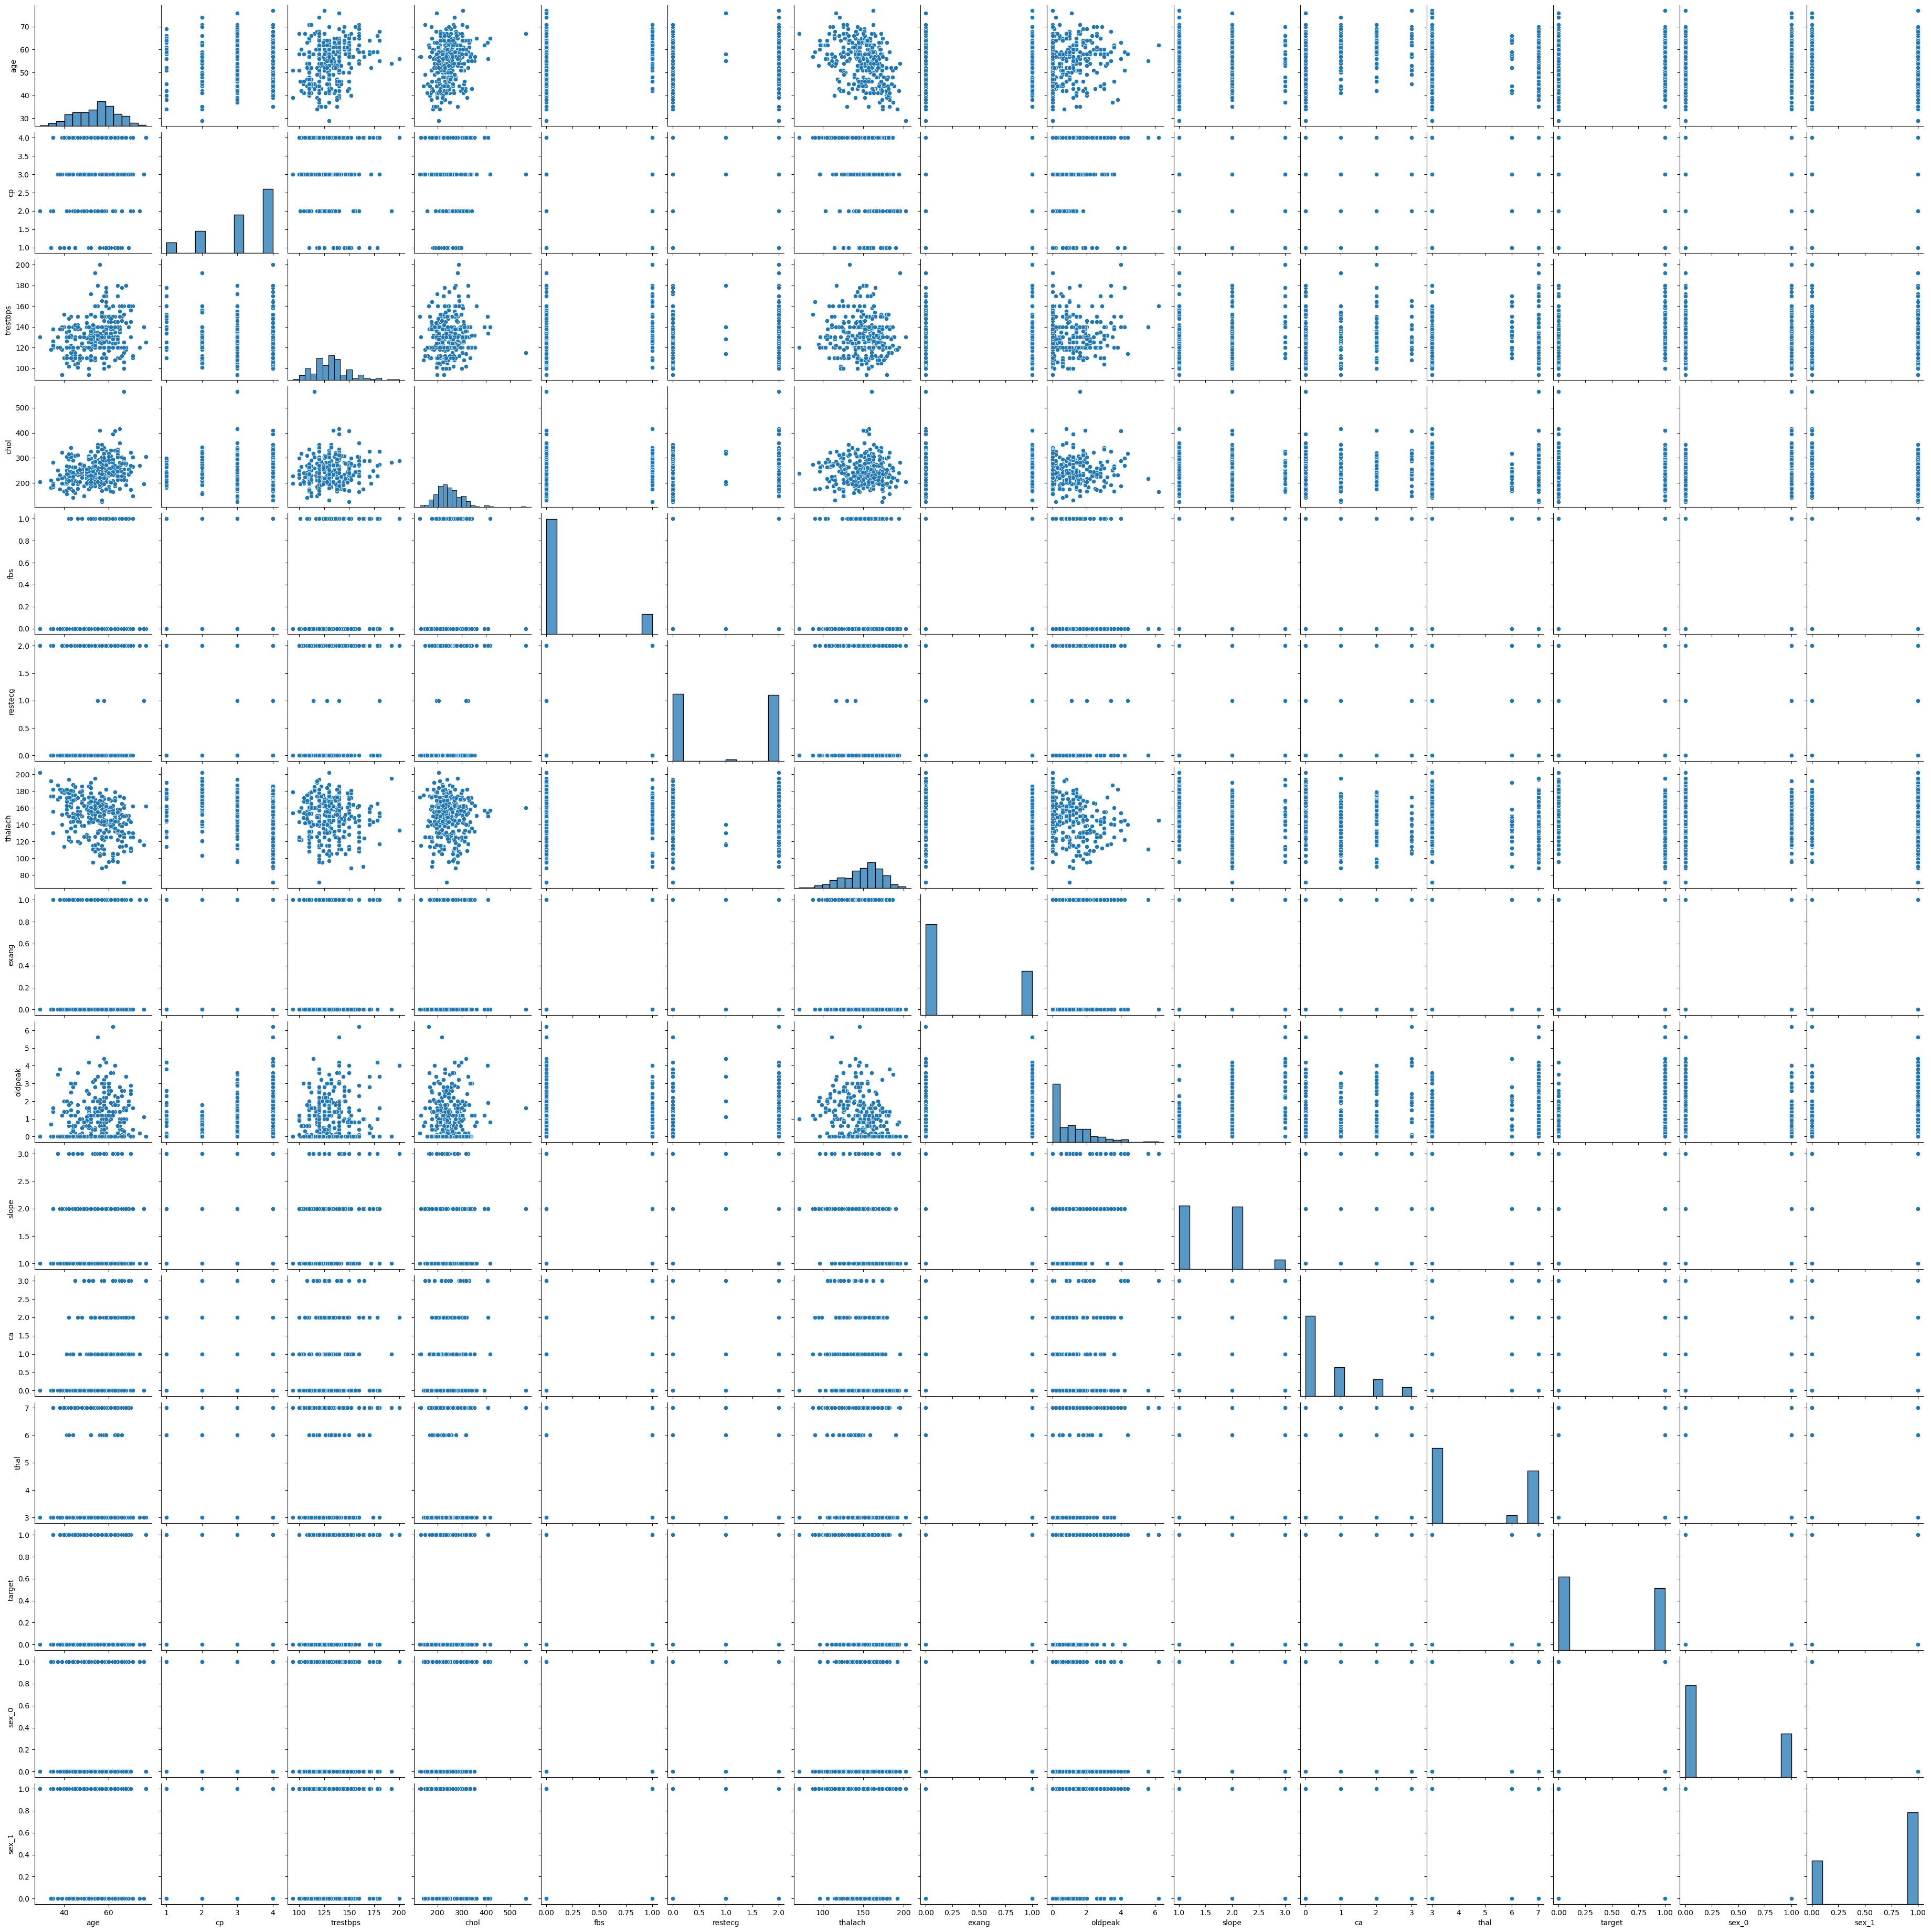

In [153]:
sns.pairplot(data)

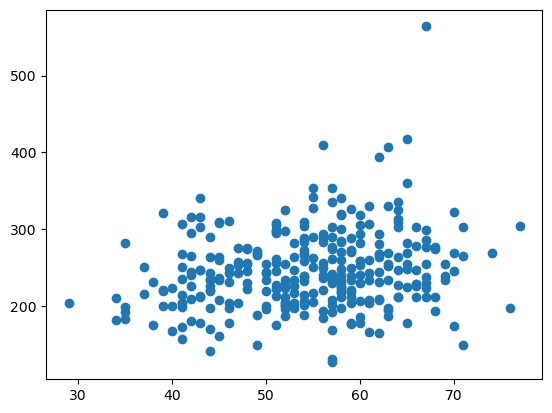

In [154]:
plt.scatter(data[['age']], data[['chol']])

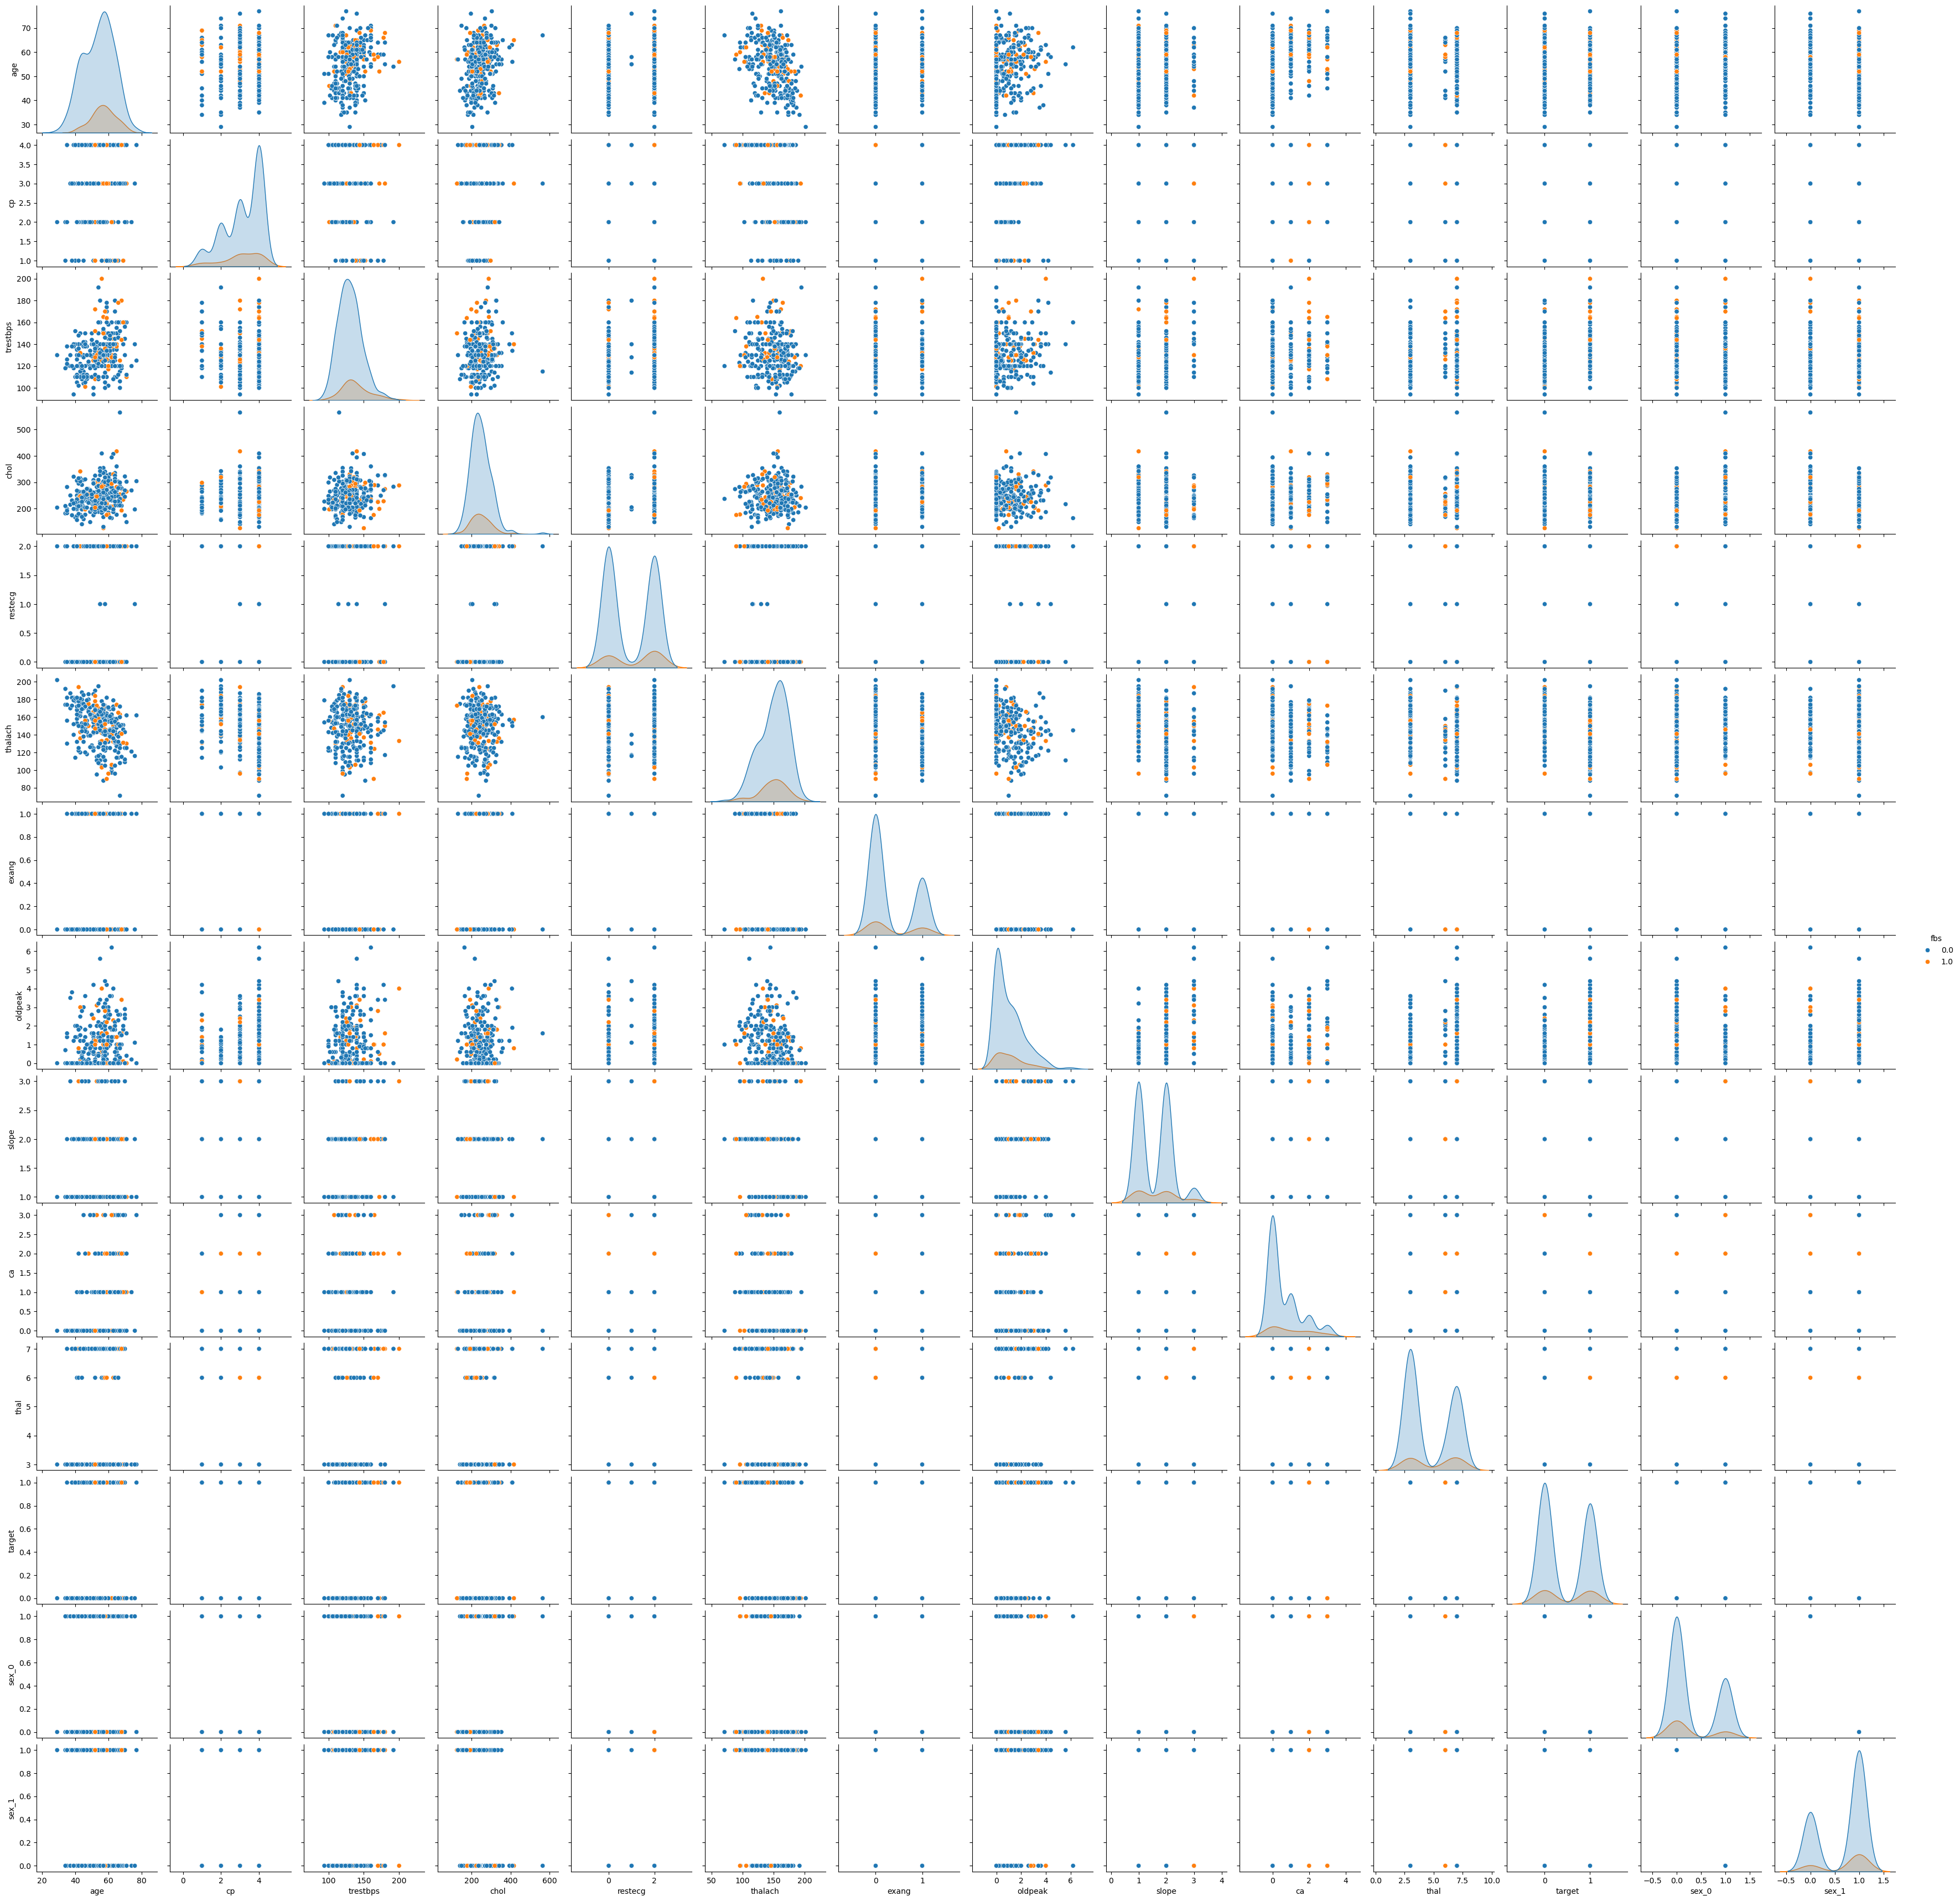

In [155]:
sns.pairplot(data, hue='fbs')

In [156]:
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split

In [157]:
df = pd.read_csv('heart-disease.csv')

In [158]:
x = df.drop('target',axis=1)

In [159]:
y = df['target']

In [160]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3, random_state=4)

In [161]:
df.shape

(303, 14)

In [162]:
x_train.shape

(212, 13)

In [163]:
x_test.shape

(91, 13)

In [164]:
y_train.shape

(212,)

In [165]:
y_test.shape

(91,)

## Model 1: Logistic Regression

In [166]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(penalty='l2',solver='newton-cg',C=5)

In [167]:
lr_model.fit(x_train,y_train)

LogisticRegression(C=5, solver='newton-cg')

In [168]:
y_pred = lr_model.predict(x_test)
y_pred

array([1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0,
       0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 0, 1])

In [169]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_pred,y_test)
accuracy

0.8461538461538461

## Model 2: K Nearest Neighbours

In [170]:
from sklearn.neighbors import KNeighborsClassifier
knn_ = KNeighborsClassifier(n_neighbors=3)
knn_.fit(x_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [171]:
yPred_Knn = knn_.predict(x_test)

In [172]:
yPred_Knn

array([1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0,
       1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0,
       0, 0, 1])

In [173]:
accuracy_Knn = accuracy_score(yPred_Knn , y_test)

In [174]:
accuracy_Knn

0.6593406593406593

## Model 3: Decision Tree

In [175]:
from sklearn.tree import DecisionTreeClassifier
dtc = DecisionTreeClassifier()
dtc.fit(x_train, y_train)

DecisionTreeClassifier()

In [176]:
yPred_dtc = dtc.predict(x_test)

In [177]:
yPred_dtc

array([1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0,
       0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0,
       1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0,
       1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       0, 0, 1])

In [178]:
accuracy_dtc = accuracy_score(yPred_dtc,y_test)

In [179]:
accuracy_dtc

0.7472527472527473

### Logistic Regression with GridSearchCV

In [180]:
val = list(np.arange(1,30,1))
val

[np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(9),
 np.int64(10),
 np.int64(11),
 np.int64(12),
 np.int64(13),
 np.int64(14),
 np.int64(15),
 np.int64(16),
 np.int64(17),
 np.int64(18),
 np.int64(19),
 np.int64(20),
 np.int64(21),
 np.int64(22),
 np.int64(23),
 np.int64(24),
 np.int64(25),
 np.int64(26),
 np.int64(27),
 np.int64(28),
 np.int64(29)]

In [181]:
from sklearn.model_selection import GridSearchCV

model_lr = LogisticRegression(penalty='l2')

parameters = {'solver':('newton-cg', 'liblinear', 'sag', 'saga'), 'C':val}

clf_lr = GridSearchCV(model_lr, parameters)
clf_lr.fit(x_train, y_train.values.ravel())

c:\Users\srira\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\srira\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\srira\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\srira\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\srira\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\srira\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter 

GridSearchCV(estimator=LogisticRegression(),
             param_grid={'C': [np.int64(1), np.int64(2), np.int64(3),
                               np.int64(4), np.int64(5), np.int64(6),
                               np.int64(7), np.int64(8), np.int64(9),
                               np.int64(10), np.int64(11), np.int64(12),
                               np.int64(13), np.int64(14), np.int64(15),
                               np.int64(16), np.int64(17), np.int64(18),
                               np.int64(19), np.int64(20), np.int64(21),
                               np.int64(22), np.int64(23), np.int64(24),
                               np.int64(25), np.int64(26), np.int64(27),
                               np.int64(28), np.int64(29)],
                         'solver': ('newton-cg', 'liblinear', 'sag', 'saga')})

In [182]:
print(clf_lr.best_params_)

{'C': np.int64(1), 'solver': 'liblinear'}


In [183]:
test_pred = clf_lr.predict(x_test)

In [184]:
acc_lr_gs = accuracy_score(test_pred, y_test)
acc_lr_gs

0.8461538461538461

In [185]:
from sklearn.metrics import confusion_matrix
confusion_matrix(test_pred,y_test)

array([[44, 10],
       [ 4, 33]])

In [186]:
from sklearn.metrics import classification_report

print(classification_report(y_test, test_pred))

              precision    recall  f1-score   support

           0       0.81      0.92      0.86        48
           1       0.89      0.77      0.82        43

    accuracy                           0.85        91
   macro avg       0.85      0.84      0.84        91
weighted avg       0.85      0.85      0.84        91



### K Nearest Neighbours with GridSearchCV

In [187]:
val = list(np.arange(1,20, 1))

In [188]:
from sklearn.neighbors import KNeighborsClassifier

neigh = KNeighborsClassifier()

parameters = {'n_neighbors':val}

clf_knn = GridSearchCV(neigh, parameters)
clf_knn.fit(x_train, y_train)

GridSearchCV(estimator=KNeighborsClassifier(),
             param_grid={'n_neighbors': [np.int64(1), np.int64(2), np.int64(3),
                                         np.int64(4), np.int64(5), np.int64(6),
                                         np.int64(7), np.int64(8), np.int64(9),
                                         np.int64(10), np.int64(11),
                                         np.int64(12), np.int64(13),
                                         np.int64(14), np.int64(15),
                                         np.int64(16), np.int64(17),
                                         np.int64(18), np.int64(19)]})

In [189]:
print(clf_knn.best_params_)

{'n_neighbors': np.int64(14)}


In [190]:
knn_test_pred = clf_knn.predict(x_test)

In [191]:
accuracy_knn_gs = accuracy_score(knn_test_pred, y_test)
accuracy_knn_gs

0.6703296703296703

KNN gave about 66% accuracy before tuning. After GridSearchCV it improved slightly to about 67%.

### Confusion Matrix

In [192]:
from sklearn.metrics import confusion_matrix
confusion_matrix(knn_test_pred,y_test)

array([[40, 22],
       [ 8, 21]])

In [193]:
print(classification_report(y_test,knn_test_pred))

              precision    recall  f1-score   support

           0       0.65      0.83      0.73        48
           1       0.72      0.49      0.58        43

    accuracy                           0.67        91
   macro avg       0.68      0.66      0.66        91
weighted avg       0.68      0.67      0.66        91



### Decision Tree with GridSearchCV

In [194]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [195]:
clf = DecisionTreeClassifier(random_state=1024)

param_grid = {
              'max_features': ['auto', 'sqrt', 'log2'],
              'ccp_alpha': [0.1, .01, .001],
              'max_depth' : np.arange(5,10,1),
              'criterion' :['gini', 'entropy']
             }

clf_dtc = GridSearchCV(clf, param_grid=param_grid, cv=5, verbose=True)

clf_dtc.fit(x_train, y_train)

Fitting 5 folds for each of 90 candidates, totalling 450 fits


c:\Users\srira\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
150 fits failed out of a total of 450.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
150 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\srira\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\srira\anaconda3\Lib\site-packages\sklearn\base.py", line 1382, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "c:\Users\srira\anaconda3\Lib\site-packages\sklearn\base.py", line 436, in _validate_params
 

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=1024),
             param_grid={'ccp_alpha': [0.1, 0.01, 0.001],
                         'criterion': ['gini', 'entropy'],
                         'max_depth': array([5, 6, 7, 8, 9]),
                         'max_features': ['auto', 'sqrt', 'log2']},
             verbose=True)

In [196]:
print(clf_dtc.best_params_)

{'ccp_alpha': 0.01, 'criterion': 'gini', 'max_depth': np.int64(8), 'max_features': 'sqrt'}


In [197]:
dtc_test_pred = clf_dtc.predict(x_test)

In [198]:
accuracy_dtc_gs = metrics.accuracy_score(y_test, dtc_test_pred)
accuracy_dtc_gs

0.8131868131868132

The Decision Tree gave about 78% accuracy before tuning. After GridSearchCV it improved to about 81%.

In [199]:
confusion_matrix(dtc_test_pred,y_test)

array([[40,  9],
       [ 8, 34]])

In [200]:
print(classification_report(y_test,dtc_test_pred))

              precision    recall  f1-score   support

           0       0.82      0.83      0.82        48
           1       0.81      0.79      0.80        43

    accuracy                           0.81        91
   macro avg       0.81      0.81      0.81        91
weighted avg       0.81      0.81      0.81        91



Comparing the three models, Logistic Regression gives the best accuracy (about 85%) and the highest ROC AUC, so it is the strongest model here.

## ROC Curve and AUC

To Plot a Graph of Receiver Operating Characteristic Curve (ROC) with FPR at the x axis and TPR at the y axis and to find the roc_auc score

In [201]:
prob_lr = clf_lr.predict_proba(x_test)
prob_knn = clf_knn.predict_proba(x_test)
prob_dtc = clf_dtc.predict_proba(x_test)

In [202]:
prob_lr =  prob_lr[:, 1]
prob_knn = prob_knn[:, 1]
prob_dtc = prob_dtc[:, 1]

In [203]:
from sklearn.metrics import roc_curve
fpr_lr, tpr_lr, thresh_lr = roc_curve(y_test, prob_lr)
fpr_knn, tpr_knn, thresh_knn = roc_curve(y_test, prob_knn)
fpr_dtc, tpr_dtc, thresh_dtc = roc_curve(y_test, prob_dtc)

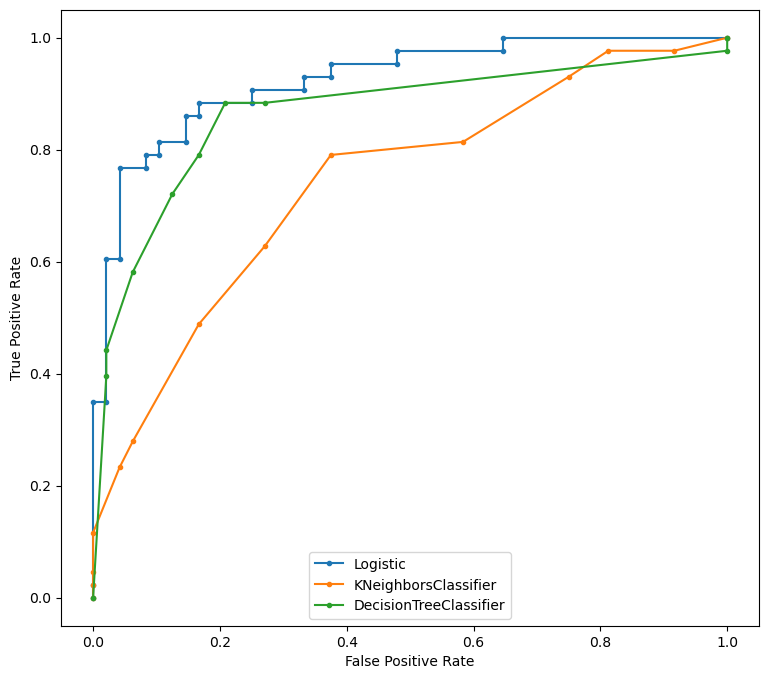

In [204]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9,8))
ax.plot(fpr_lr, tpr_lr, marker='.', label='Logistic')
ax.plot(fpr_knn, tpr_knn, marker='.', label='KNeighborsClassifier')
ax.plot(fpr_dtc, tpr_dtc, marker='.', label='DecisionTreeClassifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend(loc=8)

plt.show()

**From the above Graph it is clear that the area under the Logistic Regression curve is more than the other two curves.**

## Conclusion: Logistic Regression is the Best Model

In [205]:
from sklearn.metrics import roc_auc_score

auc_lr = roc_auc_score(y_test, prob_lr)
auc_knn = roc_auc_score(y_test, prob_knn)
auc_dtc = roc_auc_score(y_test, prob_dtc)

print(f'Logistic : ROC AUC = {round(auc_lr, 3)*100} %')
print(f'Logistic : ROC AUC = {round(auc_knn, 3)*100} %')
print(f'Logistic : ROC AUC = {round(auc_dtc, 3)*100} %')    
     

Logistic : ROC AUC = 92.4 %
Logistic : ROC AUC = 74.1 %
Logistic : ROC AUC = 86.6 %


In [206]:
# from pandas.core.window.expanding import ExpandingGroupby
# from matplotlib.projections.polar import ThetaAxis
# import pandas as pd
# import numpy as np

# n = int(input("Enter no of Patients who's Status is to be Determined :- "))

# def Prediction() :
#   age = int(input("Age of the Patient :- "))
#   sex = int(input("Sex of the Patient (0 - female & 1 - male) :- "))
#   cp = int(input("Chest Pain Type\nValue 1: typical angina\nValue 2: atypical angina\nValue 3: non-anginal pain\nValue 4: asymptomatic : \n"))
#   trestbps = int(input("Resting Blood Pressure(in mm Hg on admission to the hospital) :- "))
#   chol = int(input("Serum Cholestrol in mg/dl:- "))
#   fbs = int(input("Fasting Blood Sugar\ntrue=1\nfalse=0 :- \n"))
#   restecg = int(input("Resting ElectroCardiographic Results\nValue 0: normal\nValue 1: having ST-T wave abnormality\nValue 2: showing probable or definite left ventricular hypertrophy by Estes' criteria :- \n"))
#   thalach = int(input("Maximum Heart Rate Achieved :- "))
#   exang = int(input("Exercise-include angina\ntrue=1\nfalse=0 :- \n"))
#   oldpeak = float(input("ST Depression induced by Exercise relative to Rest :- "))
#   slope = int(input("Slope of Peak Exercise ST segment\nValue 1: upsloping\nValue 2: flat\nValue 3: downsloping :- \n"))
#   ca = int(input("No. of Major Vessels (0-3) :- "))
#   thal = int(input("Thalasemia Indicator :- "))
#   new_patient = np.array([age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal])

#   new_patient = new_patient.reshape(1,-1) #converting to 2D array

#   if clf_lr.predict(new_patient) == 0 :
#     return "The Patient with the above provided Vitals Dies!!!"
#   else :
#     return "The Patient with the above provided vitals Lives!!!"

# for i in range(n) :
#   print(Prediction())